In [ ]:
!git clone https://github.com/carrn/Shude_waveforms.git

fatal: destination path 'Shude_waveforms' already exists and is not an empty directory.


In [ ]:
# Importing packages
# --- Importing matplotlib, seaborn, etc.

import os
import random

import matplotlib as mpl
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.gridspec import GridSpec
import seaborn as sns

# !pip install numpy==1.19  # Removed explicit old numpy version installation
#import numpy as np

import pandas as pd
#import scipy
#from scipy import io
import pickle as pkl
import h5py
import xml.etree.ElementTree as ET

In [ ]:
!python --version

Python 3.12.12


In [ ]:
!pip install networkx==2.8.8
import networkx as nx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 21.9 MB/s eta 0:00:00
  Attempting uninstall: networkx
    Found existing installation: networkx 3.6.1
    Uninstalling networkx-3.6.1:
      Successfully uninstalled networkx-3.6.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
scikit-image 0.25.2 requires networkx>=3.0, but you have networkx 2.8.8 which is incompatible.
momepy 0.10.0 requires networkx>=3.2, but you have networkx 2.8.8 which is incompatible.
mapclassify 2.10.0 requires networkx>=3.2, but you have networkx 2.8.8 which is incompatible.
spopt 0.7.0 requires networkx>=3.2, but you have networkx 2.8.8 which is incompatible.


In [ ]:
import networkx as nx

#!pip install numba==0.56.0 --force-reinstall --no-cache-dir # Pin numba to a compatible version

!pip install scikit-learn
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import confusion_matrix

!pip install xgboost
import xgboost as xgb

#!pip install umap-learn==0.5.0 --force-reinstall --no-cache-dir # Ensure specific umap-learn version
#from umap import umap_ as umap

#!pip install cylouvain==0.2.2
#import cylouvain

!pip install shap
import shap

#!pip install python-igraph
#import igraph as ig

In [ ]:
!pip install ismember

In [ ]:
import scipy
from scipy import io

In [ ]:

!pip install umap-learn==0.5.3 # Ensure specific umap-learn version
from umap import umap_ as umap

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.2/88.2 kB 3.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for umap-learn: filename=umap_learn-0.5.3-py3-none-any.whl size=82810 sha256=fd8277fa09f17fe27fbb80246578ea8dfc17207c5139ec94aa648a066f2761f3
  Stored in directory: /root/.cache/pip/wheels/6b/a6/5c/466a36f7e4073169aa2ed85b749b1f56c0da07b0c86d0f7750
Successfully built umap-learn
  Attempting uninstall: umap-learn
    Found existing installation: umap-learn 0.5.9.post2
    Uninstalling umap-learn-0.5.9.post2:
      Successfully uninstalled umap-learn-0.5.9.post2


In [ ]:
"""
Pure Python implementation of the Louvain algorithm.
Converted from Cython implementation.
Author: Alexandre Hollocou <alexandre@hollocou.fr>
License: BSD 3 clause
"""

import numpy as np
from scipy import sparse
import networkx as nx
from collections import defaultdict


class PythonLouvain:
    """Python implementation of the Louvain community detection algorithm."""

    def __init__(self, adj_matrix):
        """
        Initialize with a sparse adjacency matrix.

        Parameters:
        -----------
        adj_matrix : scipy.sparse matrix
            Sparse adjacency matrix of the graph
        """
        # Stopping criteria
        self._PASS_MAX = -1
        self._MIN = 0.0000001

        # Initialize graph
        self.n_nodes = adj_matrix.shape[0]
        self.graph_neighbors = [[] for _ in range(self.n_nodes)]
        self.graph_weights = [[] for _ in range(self.n_nodes)]

        # Copy graph from sparse matrix
        indptr = adj_matrix.indptr
        indices = adj_matrix.indices
        data = np.array(adj_matrix.data, dtype=float)

        for i in range(len(indptr) - 1):
            for j in range(indptr[i], indptr[i + 1]):
                self.graph_neighbors[i].append(indices[j])
                self.graph_weights[i].append(data[j])

        # Status variables
        self.communities = []
        self.node2com = None
        self.internals = None
        self.loops = None
        self.degrees = None
        self.gdegrees = None
        self.total_weight = 0.

        # List of partitions
        self.partition_list = []

    def init_status(self):
        """Initialize internal state variables."""
        self.node2com = np.arange(self.n_nodes, dtype=int)
        self.internals = np.zeros(self.n_nodes, dtype=float)
        self.loops = np.zeros(self.n_nodes, dtype=float)
        self.degrees = np.zeros(self.n_nodes, dtype=float)
        self.gdegrees = np.zeros(self.n_nodes, dtype=float)
        self.total_weight = 0.

        # Fill internal state variables
        for node in range(self.n_nodes):
            for i, neighbor in enumerate(self.graph_neighbors[node]):
                neighbor_weight = self.graph_weights[node][i]

                if neighbor == node:
                    self.internals[node] += neighbor_weight
                    self.loops[node] += neighbor_weight
                    self.degrees[node] += 2. * neighbor_weight
                    self.gdegrees[node] += 2. * neighbor_weight
                    self.total_weight += 2. * neighbor_weight
                else:
                    self.degrees[node] += neighbor_weight
                    self.gdegrees[node] += neighbor_weight
                    self.total_weight += neighbor_weight

        self.total_weight = self.total_weight / 2.

    def remove(self, node, com, weight):
        """Remove node from its community."""
        self.node2com[node] = -1
        self.degrees[com] -= self.gdegrees[node]
        self.internals[com] -= weight + self.loops[node]

    def insert(self, node, com, weight):
        """Insert node into a community."""
        self.node2com[node] = com
        self.degrees[com] += self.gdegrees[node]
        self.internals[com] += weight + self.loops[node]

    def modularity(self, resolution):
        """Compute the modularity of the current partition."""
        result = 0.
        for com in range(self.n_nodes):
            result += resolution * self.internals[com] / self.total_weight
            result -= (self.degrees[com] / (2. * self.total_weight)) ** 2
        return result

    def neighcom(self, node):
        """Get weights to neighboring communities for a node."""
        neighbor_weight = defaultdict(float)
        for i, neighbor in enumerate(self.graph_neighbors[node]):
            if neighbor != node:
                neighborcom = self.node2com[neighbor]
                neighbor_weight[neighborcom] += self.graph_weights[node][i]
        return neighbor_weight

    def one_level(self, resolution):
        """Perform one level of community detection."""
        modified = True
        nb_pass_done = 0
        cur_mod = self.modularity(resolution)
        new_mod = cur_mod

        while modified and nb_pass_done != self._PASS_MAX:
            cur_mod = new_mod
            modified = False
            nb_pass_done += 1

            for node in range(self.n_nodes):
                node_com = self.node2com[node]
                neighbor_weight = self.neighcom(node)

                # Remove node from its community
                self.remove(node, node_com, neighbor_weight[node_com])

                # Find best community
                best_com = node_com
                best_increase = 0.

                for com, weight in neighbor_weight.items():
                    if weight > 0:
                        increase = (resolution * weight -
                                  self.degrees[com] * self.gdegrees[node] /
                                  (self.total_weight * 2.))
                        if increase > best_increase:
                            best_increase = increase
                            best_com = com

                # Insert node into best community
                self.insert(node, best_com, neighbor_weight[best_com])

                if best_com != node_com:
                    modified = True

            new_mod = self.modularity(resolution)
            if new_mod - cur_mod < self._MIN:
                break

    def renumber(self):
        """Renumber communities to be consecutive integers."""
        # Count nodes in each community
        com_n_nodes = [0] * self.n_nodes
        for node in range(self.n_nodes):
            com_n_nodes[self.node2com[node]] += 1

        # Create new indices for non-empty communities
        com_new_index = [0] * self.n_nodes
        final_index = 0
        for com in range(self.n_nodes):
            if com_n_nodes[com] > 0:
                com_new_index[com] = final_index
                final_index += 1

        # Build new communities
        new_communities = [[] for _ in range(final_index)]
        new_node2com = np.zeros(self.n_nodes, dtype=int)

        for node in range(self.n_nodes):
            new_com = com_new_index[self.node2com[node]]
            new_communities[new_com].append(node)
            new_node2com[node] = new_com

        self.communities = new_communities
        self.node2com = new_node2com

    def induced_graph(self):
        """Create induced graph from current communities."""
        new_n_nodes = len(self.communities)
        new_graph_neighbors = [[] for _ in range(new_n_nodes)]
        new_graph_weights = [[] for _ in range(new_n_nodes)]

        for com in range(new_n_nodes):
            to_insert = defaultdict(float)

            for node in self.communities[com]:
                for i, neighbor in enumerate(self.graph_neighbors[node]):
                    neighbor_com = self.node2com[neighbor]
                    neighbor_weight = self.graph_weights[node][i]

                    if neighbor == node:
                        to_insert[neighbor_com] += 2 * neighbor_weight
                    else:
                        to_insert[neighbor_com] += neighbor_weight

            for neighbor_com, weight in to_insert.items():
                new_graph_neighbors[com].append(neighbor_com)
                if neighbor_com == com:
                    new_graph_weights[com].append(weight / 2.)
                else:
                    new_graph_weights[com].append(weight)

        self.n_nodes = new_n_nodes
        self.graph_neighbors = new_graph_neighbors
        self.graph_weights = new_graph_weights

    def get_partition(self):
        """Get current partition as a list."""
        return list(self.node2com)

    def generate_dendrogram(self, resolution=1.0):
        """
        Generate dendrogram by iteratively detecting communities.

        Parameters:
        -----------
        resolution : float
            Resolution parameter for modularity

        Returns:
        --------
        list of lists
            Dendrogram showing hierarchy of community assignments
        """
        self.init_status()
        self.one_level(resolution)
        new_mod = self.modularity(resolution)
        self.renumber()
        self.partition_list.append(self.get_partition())
        mod = new_mod
        self.induced_graph()
        self.init_status()

        while True:
            self.one_level(resolution)
            new_mod = self.modularity(resolution)

            if new_mod - mod < self._MIN:
                break

            self.renumber()
            self.partition_list.append(self.get_partition())
            mod = new_mod
            self.induced_graph()
            self.init_status()

        return self.partition_list


def python_modularity(partition, adj_matrix, resolution=1.0):
    """
    Compute modularity of a partition.

    Parameters:
    -----------
    partition : array-like
        Community assignment for each node
    adj_matrix : scipy.sparse matrix
        Sparse adjacency matrix
    resolution : float
        Resolution parameter

    Returns:
    --------
    float
        Modularity value
    """
    n_nodes = adj_matrix.shape[0]
    indptr = adj_matrix.indptr
    indices = adj_matrix.indices
    data = np.array(adj_matrix.data, dtype=float)

    # Convert partition to list
    part = list(partition)

    # Compute degrees
    links = 0.
    degrees = []

    for node in range(n_nodes):
        degree = 0.
        for i in range(indptr[node], indptr[node + 1]):
            if indices[i] == node:
                degree += 2 * data[i]
                links += 2 * data[i]
            else:
                degree += data[i]
                links += data[i]
        degrees.append(degree)

    links /= 2

    # Compute internal edges and degrees per community
    inc = defaultdict(float)
    deg = defaultdict(float)

    for node in range(n_nodes):
        com = part[node]
        deg[com] += degrees[node]

        for i in range(indptr[node], indptr[node + 1]):
            neighbor = indices[i]
            edge_weight = data[i]

            if part[neighbor] == com:
                if neighbor == node:
                    inc[com] += float(edge_weight)
                else:
                    inc[com] += float(edge_weight) / 2.

    # Compute modularity
    res = 0.
    for com in deg:
        res += resolution * (inc[com] / links) - (deg[com] / (2. * links)) ** 2

    return res


def best_partition(graph, resolution=1.):
    """
    Given a graph, compute a partition of the nodes
    using the Louvain heuristic to maximize the modularity function.

    Parameters
    ----------
    graph: networkx.Graph, scipy.csr_matrix or np.ndarray
        The input graph or its adjacency matrix (sparse or dense).

    resolution: double, optional, default: 1.0
        The resolution parameter that controls the size of the communities.
        This parameter corresponds to the time introduced in
        "Laplacian Dynamics and Multiscale Modular Structure in Networks",
        R. Lambiotte, J.-C. Delvenne, M. Barahona

    Returns
    -------
    partition: dictionary
        The output partition, with communities numbered from 0 to the number of communities.
        The keys of the dictionary correspond to the nodes and the values to the communities.

    References
    ----------

    - Fast unfolding of communities in large networks, 2008
      Blondel, Vincent D and Guillaume, Jean-Loup and Lambiotte, Renaud and Lefebvre, Etienne
      Journal of statistical mechanics: theory and experiment, 2008(10), P10008.

    Notes
    -----
    Uses a pure Python version of the Louvain algorithm.

    """
    if type(graph) == sparse.csr_matrix:
        adj_matrix = graph
    elif type(graph) == np.ndarray:
        adj_matrix = sparse.csr_matrix(graph)
    elif type(graph) == nx.classes.graph.Graph:
        adj_matrix = nx.adj_matrix(graph)
    else:
        raise TypeError(
            "The argument should be a NetworkX graph, a NumPy array or a SciPy Compressed Sparse Row matrix.")

    louvain = PythonLouvain(adj_matrix)
    dendrogram = louvain.generate_dendrogram(resolution)

    partition = range(len(dendrogram[-1]))
    for i in range(1, len(dendrogram) + 1):
        new_partition = dict()
        for j in range(len(dendrogram[-i])):
            new_partition[j] = partition[dendrogram[-i][j]]
        partition = new_partition

    if type(graph) == nx.classes.graph.Graph:
        return {node: partition[i] for (i, node) in enumerate(graph.nodes())}
    else:
        return partition


def modularity(partition, graph, resolution=1.):
    """
    Compute the modularity of a node partition of a graph.

    Parameters
    ----------
    partition: dict
       The partition of the nodes.
       The keys of the dictionary correspond to the nodes and the values to the communities.

    graph: networkx.Graph, scipy.csr_matrix or np.ndarray
        The graph or its adjacency matrix (sparse or dense).

    resolution: double, optional, default: 1.0
        The resolution parameter in the modularity function.
        This parameter corresponds to the time introduced in
        "Laplacian Dynamics and Multiscale Modular Structure in Networks",
        R. Lambiotte, J.-C. Delvenne, M. Barahona

    Returns
    -------
    modularity : float
       The modularity.

    References
    ----------

    - Finding and evaluating community structure in networks, 2004
      Newman, M. E. and Girvan, M.
      Physical review E, 69(2), 026113.

    Notes
    -----
    Uses pure Python code to compute modularity.

    """
    if type(graph) == sparse.csr_matrix:
        adj_matrix = graph
    elif type(graph) == np.ndarray:
        adj_matrix = sparse.csr_matrix(graph)
    elif type(graph) == nx.classes.graph.Graph:
        adj_matrix = nx.adj_matrix(graph)
        partition = {i: partition[node] for (i, node) in enumerate(graph.nodes())}
    else:
        raise TypeError(
            "The argument should be a NetworkX graph, a NumPy array or a SciPy Compressed Sparse Row matrix.")

    return python_modularity(partition, adj_matrix, resolution)

In [ ]:
"""
Fast implementation of the Louvain algorithm in pure Python.
Converted from Cython implementation.
Author: Alexandre Hollocou <alexandre@hollocou.fr>
License: 3-clause BSD
"""

import numpy as np
from collections import defaultdict


class PythonLouvain:
    """Python implementation of the Louvain community detection algorithm."""

    def __init__(self, adj_matrix):
        """
        Initialize with a sparse adjacency matrix.

        Parameters:
        -----------
        adj_matrix : scipy.sparse matrix
            Sparse adjacency matrix of the graph
        """
        # Stopping criteria
        self._PASS_MAX = -1
        self._MIN = 0.0000001

        # Initialize graph
        self.n_nodes = adj_matrix.shape[0]
        self.graph_neighbors = [[] for _ in range(self.n_nodes)]
        self.graph_weights = [[] for _ in range(self.n_nodes)]

        # Copy graph from sparse matrix
        indptr = adj_matrix.indptr
        indices = adj_matrix.indices
        data = np.array(adj_matrix.data, dtype=float)

        for i in range(len(indptr) - 1):
            for j in range(indptr[i], indptr[i + 1]):
                self.graph_neighbors[i].append(indices[j])
                self.graph_weights[i].append(data[j])

        # Status variables
        self.communities = []
        self.node2com = None
        self.internals = None
        self.loops = None
        self.degrees = None
        self.gdegrees = None
        self.total_weight = 0.

        # List of partitions
        self.partition_list = []

    def init_status(self):
        """Initialize internal state variables."""
        self.node2com = np.arange(self.n_nodes, dtype=int)
        self.internals = np.zeros(self.n_nodes, dtype=float)
        self.loops = np.zeros(self.n_nodes, dtype=float)
        self.degrees = np.zeros(self.n_nodes, dtype=float)
        self.gdegrees = np.zeros(self.n_nodes, dtype=float)
        self.total_weight = 0.

        # Fill internal state variables
        for node in range(self.n_nodes):
            for i, neighbor in enumerate(self.graph_neighbors[node]):
                neighbor_weight = self.graph_weights[node][i]

                if neighbor == node:
                    self.internals[node] += neighbor_weight
                    self.loops[node] += neighbor_weight
                    self.degrees[node] += 2. * neighbor_weight
                    self.gdegrees[node] += 2. * neighbor_weight
                    self.total_weight += 2. * neighbor_weight
                else:
                    self.degrees[node] += neighbor_weight
                    self.gdegrees[node] += neighbor_weight
                    self.total_weight += neighbor_weight

        self.total_weight = self.total_weight / 2.

    def remove(self, node, com, weight):
        """Remove node from its community."""
        self.node2com[node] = -1
        self.degrees[com] -= self.gdegrees[node]
        self.internals[com] -= weight + self.loops[node]

    def insert(self, node, com, weight):
        """Insert node into a community."""
        self.node2com[node] = com
        self.degrees[com] += self.gdegrees[node]
        self.internals[com] += weight + self.loops[node]

    def modularity(self, resolution):
        """Compute the modularity of the current partition."""
        result = 0.
        for com in range(self.n_nodes):
            result += resolution * self.internals[com] / self.total_weight
            result -= (self.degrees[com] / (2. * self.total_weight)) ** 2
        return result

    def neighcom(self, node):
        """Get weights to neighboring communities for a node."""
        neighbor_weight = defaultdict(float)
        for i, neighbor in enumerate(self.graph_neighbors[node]):
            if neighbor != node:
                neighborcom = self.node2com[neighbor]
                neighbor_weight[neighborcom] += self.graph_weights[node][i]
        return neighbor_weight

    def one_level(self, resolution):
        """Perform one level of community detection."""
        modified = True
        nb_pass_done = 0
        cur_mod = self.modularity(resolution)
        new_mod = cur_mod

        while modified and nb_pass_done != self._PASS_MAX:
            cur_mod = new_mod
            modified = False
            nb_pass_done += 1

            for node in range(self.n_nodes):
                node_com = self.node2com[node]
                neighbor_weight = self.neighcom(node)

                # Remove node from its community
                self.remove(node, node_com, neighbor_weight[node_com])

                # Find best community
                best_com = node_com
                best_increase = 0.

                for com, weight in neighbor_weight.items():
                    if weight > 0:
                        increase = (resolution * weight -
                                  self.degrees[com] * self.gdegrees[node] /
                                  (self.total_weight * 2.))
                        if increase > best_increase:
                            best_increase = increase
                            best_com = com

                # Insert node into best community
                self.insert(node, best_com, neighbor_weight[best_com])

                if best_com != node_com:
                    modified = True

            new_mod = self.modularity(resolution)
            if new_mod - cur_mod < self._MIN:
                break

    def renumber(self):
        """Renumber communities to be consecutive integers."""
        # Count nodes in each community
        com_n_nodes = [0] * self.n_nodes
        for node in range(self.n_nodes):
            com_n_nodes[self.node2com[node]] += 1

        # Create new indices for non-empty communities
        com_new_index = [0] * self.n_nodes
        final_index = 0
        for com in range(self.n_nodes):
            if com_n_nodes[com] > 0:
                com_new_index[com] = final_index
                final_index += 1

        # Build new communities
        new_communities = [[] for _ in range(final_index)]
        new_node2com = np.zeros(self.n_nodes, dtype=int)

        for node in range(self.n_nodes):
            new_com = com_new_index[self.node2com[node]]
            new_communities[new_com].append(node)
            new_node2com[node] = new_com

        self.communities = new_communities
        self.node2com = new_node2com

    def induced_graph(self):
        """Create induced graph from current communities."""
        new_n_nodes = len(self.communities)
        new_graph_neighbors = [[] for _ in range(new_n_nodes)]
        new_graph_weights = [[] for _ in range(new_n_nodes)]

        for com in range(new_n_nodes):
            to_insert = defaultdict(float)

            for node in self.communities[com]:
                for i, neighbor in enumerate(self.graph_neighbors[node]):
                    neighbor_com = self.node2com[neighbor]
                    neighbor_weight = self.graph_weights[node][i]

                    if neighbor == node:
                        to_insert[neighbor_com] += 2 * neighbor_weight
                    else:
                        to_insert[neighbor_com] += neighbor_weight

            for neighbor_com, weight in to_insert.items():
                new_graph_neighbors[com].append(neighbor_com)
                if neighbor_com == com:
                    new_graph_weights[com].append(weight / 2.)
                else:
                    new_graph_weights[com].append(weight)

        self.n_nodes = new_n_nodes
        self.graph_neighbors = new_graph_neighbors
        self.graph_weights = new_graph_weights

    def get_partition(self):
        """Get current partition as a list."""
        return list(self.node2com)

    def generate_dendrogram(self, resolution=1.0):
        """
        Generate dendrogram by iteratively detecting communities.

        Parameters:
        -----------
        resolution : float
            Resolution parameter for modularity

        Returns:
        --------
        list of lists
            Dendrogram showing hierarchy of community assignments
        """
        self.init_status()
        self.one_level(resolution)
        new_mod = self.modularity(resolution)
        self.renumber()
        self.partition_list.append(self.get_partition())
        mod = new_mod
        self.induced_graph()
        self.init_status()

        while True:
            self.one_level(resolution)
            new_mod = self.modularity(resolution)

            if new_mod - mod < self._MIN:
                break

            self.renumber()
            self.partition_list.append(self.get_partition())
            mod = new_mod
            self.induced_graph()
            self.init_status()

        return self.partition_list


def modularity(partition, adj_matrix, resolution=1.0):
    """
    Compute modularity of a partition.

    Parameters:
    -----------
    partition : array-like
        Community assignment for each node
    adj_matrix : scipy.sparse matrix
        Sparse adjacency matrix
    resolution : float
        Resolution parameter

    Returns:
    --------
    float
        Modularity value
    """
    n_nodes = adj_matrix.shape[0]
    indptr = adj_matrix.indptr
    indices = adj_matrix.indices
    data = np.array(adj_matrix.data, dtype=float)

    # Convert partition to list
    part = list(partition)

    # Compute degrees
    links = 0.
    degrees = []

    for node in range(n_nodes):
        degree = 0.
        for i in range(indptr[node], indptr[node + 1]):
            if indices[i] == node:
                degree += 2 * data[i]
                links += 2 * data[i]
            else:
                degree += data[i]
                links += data[i]
        degrees.append(degree)

    links /= 2

    # Compute internal edges and degrees per community
    inc = defaultdict(float)
    deg = defaultdict(float)

    for node in range(n_nodes):
        com = part[node]
        deg[com] += degrees[node]

        for i in range(indptr[node], indptr[node + 1]):
            neighbor = indices[i]
            edge_weight = data[i]

            if part[neighbor] == com:
                if neighbor == node:
                    inc[com] += float(edge_weight)
                else:
                    inc[com] += float(edge_weight) / 2.

    # Compute modularity
    res = 0.
    for com in deg:
        res += resolution * (inc[com] / links) - (deg[com] / (2. * links)) ** 2

    return res

In [ ]:
!pip install python-igraph
import igraph as ig

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 44.5 MB/s eta 0:00:00


ECG function...Skip unless generating

In [ ]:
def community_ecg(self, weights=None, ens_size=16, min_weight=0.05):
    W = [0]*self.ecount()
    ## Ensemble of level-1 Louvain
    for i in range(ens_size):
        p = np.random.permutation(self.vcount()).tolist()
        g = self.permute_vertices(p)
        l = g.community_multilevel(weights=weights, return_levels=True)[0].membership
        b = [l[p[x.tuple[0]]]==l[p[x.tuple[1]]] for x in self.es]
        W = [W[i]+b[i] for i in range(len(W))]
    W = [min_weight + (1-min_weight)*W[i]/ens_size for i in range(len(W))]
    ## Force min_weight outside 2-core
    core = self.shell_index()
    ecore = [min(core[x.tuple[0]],core[x.tuple[1]]) for x in self.es]
    w = [W[i] if ecore[i]>1 else min_weight for i in range(len(ecore))]
    part = self.community_multilevel(weights=w)
    part.W = w
    part.CSI = 1-2*np.sum([min(1-i,i) for i in w])/len(w)
    return part

ig.Graph.community_ecg = community_ecg

Cluster Colors

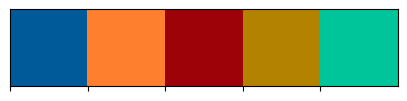

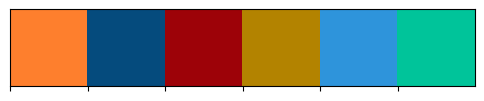

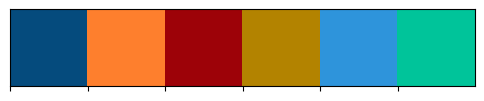

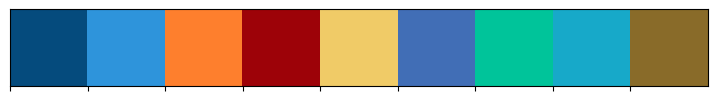

In [ ]:
# all colors
CUSTOM_PAL_SORT_3 = ['#005999','#fe7f2d','#9d0208','#b38300','#00c49a','#7bdff2','#5e60ce','#efa6c9','#ced4da','#d62424','#12db41','#f0c905','#248cd6', '#3366ff','#0099cc']
# 420
#CUSTOM_PAL_SORT_3 = ['#00c49a','#fe7f2d','#005999','#9d0208']#,'#b38300','#7bdff2','#5e60ce','#efa6c9','#ced4da','#d62424','#12db41','#f0c905','#248cd6', '#3366ff','#0099cc']
# 5 clusters
#CUSTOM_PAL_SORT_3 = ['#00c49a','#fe7f2d','#005999','#9d0208','#b38300']#,'#7bdff2','#5e60ce','#efa6c9','#ced4da','#d62424','#12db41','#f0c905','#248cd6', '#3366ff','#0099cc']
nColors =  9

CUSTOM_PAL_SORT_3 = CUSTOM_PAL_SORT_3[0:nColors]

res2_5 = ['#005999','#fe7f2d','#9d0208','#b38300','#00c49a']

res2_0 = ['#fe7f2d','#054b7d','#9d0208','#b38300','#2e94db','#00c49a']

res1_5 = ['#054b7d','#fe7f2d','#9d0208','#b38300','#2e94db','#00c49a']

res1_0 = ['#054b7d','#2e94db','#fe7f2d','#9d0208','#f0cb67','#416EB6','#00c49a','#17A9C9','#896B29']


CUSTOM_PAL_SORT_3 = res1_0





GMM_PAL = ['#d62424','#12db41','#f0c905','#248cd6']

Warm_colors = ['#fe7f2d','#9d0208']#,'#b38300'] #,'#e85d04','#dc2f02','#9d0208','#6a040f'] #ff66ff
Cold_colors = ['#00c49a','#005999']#, '#7bdff2']#'#00b4d8', '#0077b6', '#03045e']
#CUSTOM_PAL_SORT_3 = (Warm_colors, Cold_colors)

#CUSTOM_PAL_SORT_3 = join([Cold_colors],[Warm_colors])
blues = sns.color_palette("Blues")
CUSTOM_PAL_SORT_4 = blues[0:nColors]
# In RGB form
coherence_colors = [[0.609, 0.283,	0.724],
[0.259,	0.314, 0.635],
[0.251,	0.412, 0.698],
[0.176,	0.631, 0.859],
[0.369,	0.749, 0.549],
[0.898,	0.654, 0.169],
[0.898,	0.41, 0.165]]
sns.palplot(res2_5)
sns.palplot(res2_0)
sns.palplot(res1_5)
sns.palplot(res1_0)
#sns.palplot(CUSTOM_PAL_SORT_3)
#sns.palplot(CUSTOM_PAL_SORT_4)
#sns.palplot(blues)


In [ ]:
#These are the depths that the V-probe channels are located at
DEPTHS = [0.15,0.3,0.45,0.60,0.75,0.9,1.05,1.20,1.35,1.50,1.65,1.80,1.95,2.1,2.25,2.4]

#This converts time points to real time. There are 82 samples per waveform colleted at 30 kilosamples
SAMP_RATE_TO_TIME = 1/(82/30000)

#Setting of random seed across Python kernel and packages to ensure reproducibility
RAND_STATE=50
np.random.seed(RAND_STATE)
os.environ['PYTHONHASHSEED'] = str(RAND_STATE)
random.seed(RAND_STATE)

#UMAP Parameters
#The number of neighbors considered when constructing the high-d graph.
#Made more global-information preserving by increasing it from 15 to 20.
N_NEIGHBORS =  20#30 #36 #20

#The minimum distance between points in the projected space.
#Used for visualization but doesn't affect clustering.
MIN_DIST = 0.2 # 0.1

#Louvain Clustering Parameters
#increase resolution parameter to fewer clusters
RESOLUTION = 1.0 #1.0 #2.0 # 1.5 #2.5

# BLUE COLOR
BlueCol = '\033[94m'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
os.path.exists('/content/drive/MyDrive/Shude Data/5-16-2022')

True

In [ ]:
## Postitive Spiking Waveforms
from ismember import ismember
import numpy as np

print(BlueCol + 'Loading data')

rel_path = os.getcwd()


fullDataPath = os.path.join(rel_path,'drive/MyDrive/Shude Data/5-16-2022/normalizedposwaveforms5.mat');
filtfulldfPath = os.path.join(rel_path,'drive/MyDrive/Shude Data/5-16-2022/depth_pos5.mat');
ID_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/5-16-2022/ID_pos5.mat');
full_data = scipy.io.loadmat(fullDataPath)['align_pos']
depth_data = scipy.io.loadmat(filtfulldfPath)['depth_pos']
ID_data = scipy.io.loadmat(ID_path)['ID_pos']

normwaveform_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/normposwaveform.eps');
figure2_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/posclusters.eps');
clusters1_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/posclusters1.eps');
clusters2_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/posclusters2.eps');
clusters3_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/posclusters3.eps');
clusters4_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/posclusters4.eps');
clusters5_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/posclusters5.eps');
figure7_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/poslaminar.eps');
figure8_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/poslaminar2.eps');
figure9_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/posconfusionmatrix.eps');

#fullDataPath = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/2 7 22/normalizedwaveforms2.mat');
#filtfulldfPath = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/2 7 22/depth2.mat');
#ID_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/2 7 22/ID2.mat');
#full_data = scipy.io.loadmat(fullDataPath)['align_all']
#depth_data = scipy.io.loadmat(filtfulldfPath)['depth_all']
#ID_data = scipy.io.loadmat(ID_path)['ID_all']


#GMMclasslabelpath = os.path.join(rel_path,'WaveMAP_Paper/data/waveformsClassified_250hz_refiltered.mat')
#GMMfeaturepath = os.path.join(rel_path,'WaveMAP_Paper/data/gmm_features.mat')
#BICpath = os.path.join(rel_path,'WaveMAP_Paper/data/BIC_list.mat')
#eightclassGMMpath = os.path.join(rel_path,'WaveMAP_Paper/data/8_class_GMM.mat');



functional_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/functional_data.mat');

#print(rel_path)

print(fullDataPath);

#print(GMMclasslabelpath)
#print(GMMfeaturepath)
#print(BICpath)
#print(eightclassGMMpath)
#print(filtfulldfPath)

#functional_data = scipy.io.loadmat(functional_path)['stim_on']
print(full_data.shape)
print(depth_data.shape)
print(ID_data.shape)
#print(functional_data.shape)


#allDataDFPath = os.path.join(rel_path,'WaveMAP_Paper/data/full_data_df.pkl');

#GMM_class_labels = scipy.io.loadmat(GMMclasslabelpath)['classifies'].T
#gmm_features_data = scipy.io.loadmat(GMMfeaturepath)['features']

#GMM_class_labels = GMM_class_labels[~np.isnan(GMM_class_labels)]
#GMM_class_df = pd.DataFrame(GMM_class_labels,columns=['Class'])
#gmm_feat_data_nonan = gmm_features_data[~np.isnan(gmm_features_data)].reshape(len(GMM_class_df),3)

#BIC_list = scipy.io.loadmat(BICpath)['BIC_list'][0]

#eight_GMM_classes = scipy.io.loadmat(eightclassGMMpath)['classifies']

#all_data_df = pkl.load(open(allDataDFPath,'rb'))
#filt_full_df = pkl.load(open(filtfulldfPath,"rb"))

#print(ID_data)

Loading data
/content/drive/MyDrive/Shude Data/5-16-2022/normalizedposwaveforms5.mat
(105, 52)
(105, 1)
(105, 2)


In [ ]:
## Negative Spiking Waveforms
from ismember import ismember
import numpy as np

print(BlueCol + 'Loading data')

rel_path = os.getcwd()

fullDataPath = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/normalizednegwaveforms6.mat');
filtfulldfPath = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/depth_neg_scaled6.mat');
ID_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/ID_neg6.mat');
full_data = scipy.io.loadmat(fullDataPath)['align_neg']
depth_data = scipy.io.loadmat(filtfulldfPath)['depth_neg_scaled']
ID_data = scipy.io.loadmat(ID_path)['ID_neg']

normwaveform_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/normwaveform.eps');
figure2_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/clusters.eps');
clusters1_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/clusters1.eps');
clusters2_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/clusters2.eps');
clusters3_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/clusters3.eps');
clusters4_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/clusters4.eps');
clusters5_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/clusters5.eps');
clusters6_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/clusters6.eps');
clusters7_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/clusters7.eps');
clusters8_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/clusters8.eps');
clusters9_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/clusters9.eps');
figure7_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/laminar.eps');
figure8_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/laminar2.eps');
figure9_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/confusionmatrix.eps');
figure10_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/ECG.eps');
figure11_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/res_mod.eps');




print(full_data.shape)
print(depth_data.shape)
print(ID_data.shape)


Loading data
(801, 52)
(801, 1)
(801, 2)


In [ ]:
## Negative Spiking Waveforms
from ismember import ismember
import numpy as np

print(BlueCol + 'Loading data')

rel_path = os.getcwd()

fullDataPath = os.path.join(rel_path,'drive/MyDrive/Shude Data/3-2-2023/normalizednegwaveforms6.mat');
filtfulldfPath = os.path.join(rel_path,'drive/MyDrive/Shude Data/3-2-2023/depth_neg_scaled6.mat');
ID_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/3-2-2023/ID_neg6.mat');
full_data = scipy.io.loadmat(fullDataPath)['align_neg']
depth_data = scipy.io.loadmat(filtfulldfPath)['depth_neg_scaled']
ID_data = scipy.io.loadmat(ID_path)['ID_neg']

#normwaveform_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/3-2-2023/normwaveform.eps');
#figure2_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/3-2-2023/clusters.eps');
#clusters1_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/3-2-2023/clusters1.eps');
#clusters2_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/3-2-2023/clusters2.eps');
#clusters3_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/3-2-2023/clusters3.eps');
#clusters4_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/3-2-2023/clusters4.eps');
#clusters5_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/3-2-2023/clusters5.eps');
#clusters6_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/3-2-2023/clusters6.eps');
#clusters7_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/3-2-2023/clusters7.eps');
#clusters8_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/3-2-2023/clusters8.eps');
#clusters9_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/3-2-2023/clusters9.eps');
#figure7_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/3-2-2023/laminar.eps');
#figure8_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/3-2-2023/laminar2.eps');
#figure9_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/3-2-2023/confusionmatrix.eps');
#figure10_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/3-2-2023/ECG.eps');
#figure11_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/3-2-2023/res_mod.eps');

normwaveform_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/normwaveform.eps');
figure2_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/clusters.eps');
clusters1_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/clusters1.eps');
clusters2_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/clusters2.eps');
clusters3_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/clusters3.eps');
clusters4_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/clusters4.eps');
clusters5_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/clusters5.eps');
clusters6_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/clusters6.eps');
clusters7_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/clusters7.eps');
clusters8_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/clusters8.eps');
clusters9_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/clusters9.eps');
figure7_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/laminar.eps');
figure8_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/laminar2.eps');
figure9_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/confusionmatrix.eps');
figure10_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/ECG.eps');
figure11_path = os.path.join(rel_path,'drive/MyDrive/Chand Lab/Shude Data/3 2 2023/res_mod.eps');


print(full_data.shape)
print(depth_data.shape)
print(ID_data.shape)


Loading data


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Shude Data/3 2 2023/normalizednegwaveforms6.mat'

In [ ]:
maxsession = 5
sessionIDs = np.arange(1,maxsession+1)
iloc, sessionsidx = ismember(ID_data[:,1], sessionIDs) ;
print(sessionIDs)
#print(a.shape)
full_data = full_data[iloc];
depth_data = depth_data[iloc];
ID_data = ID_data[iloc];
print(full_data.shape)

[1 2 3 4 5]
(801, 52)


Plotting Waveforms

Plotting: 801 Waveforms


Text(0.5, 1.0, 'Normalized Waveforms')

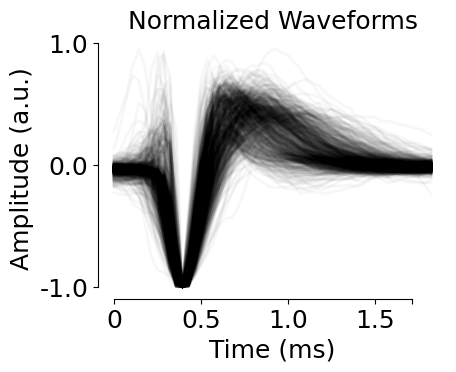

In [ ]:
# This plots all the normalized single unit waveforms together. The total waveform length is 48 points at 30000 samples/s
# 14, 28, 42 are the 0.5 ms, 1.0 ms, and 1.5 ms

# Generate subplots
f, arr = plt.subplots(1,figsize=[4.5,3.4])

print(BlueCol + "Plotting: " + str(full_data.shape[0]) + " Waveforms")
for i in range(0,full_data.shape[0]):
    arr.plot(full_data[i].T, c = 'k', alpha = 0.03,linewidth=2.);

arr.tick_params(direction='out',colors='k', axis='both')

# Set various x and y axes and labels etc.
arr.spines['top'].set_visible(False)
arr.spines['right'].set_visible(False)

arr.spines['left'].set_bounds(-1,1)
arr.spines['bottom'].set_bounds(0,48)

arr.set_xlabel('Time (ms)', fontsize=18);
arr.set_xticks([0,14,28,42,48])
arr.set_xticklabels(['0','0.5','1.0','1.5',''],fontsize=18)

arr.set_ylabel('Amplitude (a.u.)', fontsize=18)
arr.set_yticks([-1.0,0.0,1.0]);
arr.set_yticklabels([-1.0,0.0,1.0], fontsize=18);

arr.set_title('Normalized Waveforms', fontsize=18)

# Plot the data
#plt.tight_layout()
#plt.draw
#plt.savefig(normwaveform_path, bbox_inches='tight', format='eps', dpi=300)

In [ ]:
# Plot the data
plt.tight_layout()
plt.draw
plt.savefig(normwaveform_path, bbox_inches='tight', format='eps', dpi=300)

<Figure size 640x480 with 0 Axes>

UMAP and Louvain Clustering

In [ ]:
reducer = umap.UMAP(n_neighbors = N_NEIGHBORS, min_dist=MIN_DIST,
                    random_state=RAND_STATE)
mapper = reducer.fit(full_data)
embedding = reducer.transform(full_data)

umap_df = pd.DataFrame(embedding, columns=('x', 'y'))
umap_df['waveform'] = list(full_data)

In [ ]:
#from louvain import best_partition, modularity

G = nx.from_scipy_sparse_array(mapper.graph_)
clustering = best_partition(G, resolution = RESOLUTION)
clustering_solution = list(clustering.values())
umap_df['color'] = clustering_solution

cluster_colors = [CUSTOM_PAL_SORT_3[i] for i in clustering_solution]
#cluster_colors = [blues[i] for i in clustering_solution]

/tmp/ipython-input-1777986111.py:363: DeprecationWarning: adj_matrix is deprecated and will be removed in version 3.0.
Use `adjacency_matrix` instead

  adj_matrix = nx.adj_matrix(graph)
/usr/local/lib/python3.12/dist-packages/networkx/linalg/graphmatrix.py:187: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  return adjacency_matrix(G, nodelist, dtype, weight)


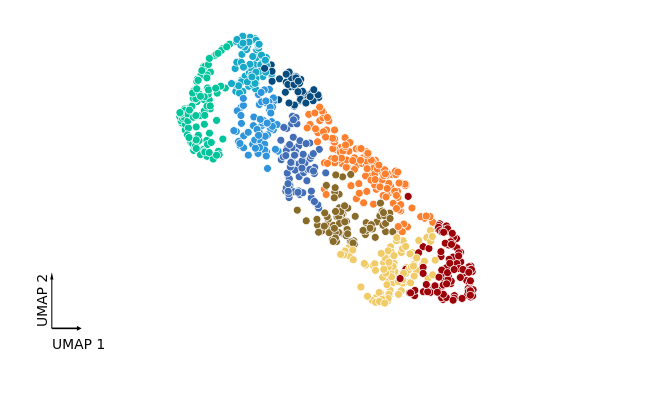

In [ ]:
f,arr = plt.subplots(1,figsize=[7,4.5],tight_layout = {'pad': 0});
f.tight_layout()
arr.scatter(umap_df['x'].tolist(), umap_df['y'].tolist(),
            marker='o', c=cluster_colors, s=32, edgecolor='w',
            linewidth=0.5)
arr.spines['top'].set_visible(False)
arr.spines['bottom'].set_visible(False)
arr.spines['left'].set_visible(False)
arr.spines['right'].set_visible(False)
arr.set_xticks([]);
arr.set_yticks([]);
arr.set_xlim(-10,20)
arr.set_ylim(-3,9)
arr.arrow(-8,-0.8,0,1.5, width=0.05, shape="full", ec="none", fc="black")
arr.arrow(-8,-0.8,1.2,0, width=0.05, shape="full", ec="none", fc="black")

arr.text(-8,-1.3,"UMAP 1", va="center")
arr.text(-8.7,-0.7,"UMAP 2",rotation=90, ha="left", va="bottom")
############

N_CLUST = len(set(clustering_solution))
#plt.savefig(figure2_path, bbox_inches='tight', format='eps', dpi = 300)
f.savefig(figure2_path,dpi = 300)

In [ ]:
figure2_path = os.path.join(rel_path,'drive/MyDrive/Shude Data/9-13-2022/clusters.eps');
f.savefig(figure2_path,dpi = 300)

In [ ]:
preferred_order = [6, 2, 3, 4, 8, 0, 1, 5, 7];
print(preferred_order)
original_order = np.arange(0,8)
for i in original_order:
  #print(preferred_order[i])

  print(preferred_order[i])
  print(original_order[i])

  print(' ')

[6, 2, 3, 4, 8, 0, 1, 5, 7]
6
0
 
2
1
 
3
2
 
4
3
 
8
4
 
0
5
 
1
6
 
5
7
 


In [ ]:
#print(clustering_solution)
#sns.palplot(CUSTOM_PAL_SORT_3)
clustering_mask = np.array(clustering_solution)


blanks = np.shape(clustering_solution)
clustering_empty = np.zeros(blanks)
for i in preferred_order:
  clustering_mask[clustering_mask == 1] = 6

print(clustering_mask)
#CUSTOM_PAL_SORT_3 = [CUSTOM_PAL_SORT_3[i] for i in preferred_order]
#sns.palplot(CUSTOM_PAL_SORT_3)

[4 4 4 4 4 4 2 4 4 2 6 2 0 0 2 0 0 6 6 4 6 3 6 3 6 2 3 3 3 6 6 3 4 0 0 0 0
 0 0 0 0 0 0 0 0 6 0 4 0 0 6 4 3 6 6 3 6 6 3 0 3 3 6 2 6 0 6 3 0 3 3 3 3 3
 2 3 3 2 2 4 3 6 3 0 0 0 0 0 0 6 0 6 6 3 3 0 0 3 0 3 4 2 2 2 0 2 2 3 3 0 6
 4 2 2 2 2 6 2 2 3 3 2 2 2 3 0 6 0 4 6 0 3 3 2 3 6 3 6 3 3 2 3 3 3 3 3 0 4
 0 3 3 6 3 0 0 4 6 0 0 6 0 0 0 0 0 0 6 0 4 0 0 0 0 0 2 0 0 2 6 0 0 0 0 0 0
 4 6 0 4 6 6 0 6 2 0 6 3 0 2 4 3 0 3 6 6 3 6 2 3 2 3 3 0 2 3 0 4 2 2 2 0 0
 3 6 6 3 3 3 3 0 0 3 3 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 3 6 6 3 3 6 0 0 4 2
 2 6 6 6 0 3 6 6 4 2 3 0 4 3 0 0 3 4 4 2 4 2 3 2 2 4 2 2 2 2 4 2 4 0 0 0 2
 0 2 2 6 2 3 2 2 0 2 3 6 4 0 6 6 3 6 3 2 3 6 3 2 6 3 3 3 3 2 2 3 3 3 3 6 6
 3 2 4 3 3 4 3 0 6 0 3 0 0 6 0 0 0 0 0 0 0 3 0 0 6 3 0 2 4 0 0 0 0 0 0 0 0
 0 6 4 3 3 6 6 6 2 3 3 3 0 3 3 3 3 2 2 0 6 0 0 3 3 3 3 2 3 6 3 2 3 3 3 3 2
 6 0 4 4 2 0 2 4 2 0 0 0 2 2 6 6 3 0 2 3 3 3 3 2 6 4 4 6 6 0 6 4 0 6 3 6 3
 3 6 6 3 0 2 0 3 0 6 3 6 3 6 3 3 3 3 0 3 6 3 6 6 6 3 3 0 3 2 0 0 0 3 0 0 0
 0 4 4 4 4 4 6 4 4 4 6 0 

ECG Clustering

In [ ]:
umap_igraph = ig.Graph(len(G), list(zip(*list(zip(*nx.to_edgelist(G)))[:2])))

umap_ECG = umap_igraph.community_ecg(ens_size=10,min_weight=0.5)

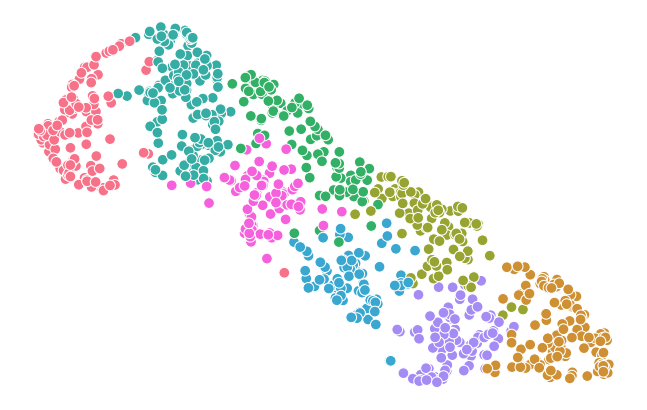

In [ ]:
umap_df = pd.DataFrame(embedding, columns=('x', 'y'))
umap_df['color'] = umap_ECG.membership

ecg_colormap = [sns.color_palette("husl", len(set(umap_ECG.membership)))[i] for i in umap_ECG.membership]

f, arr = plt.subplots(1,figsize=[7,4.5],tight_layout = {'pad': 0})
f.tight_layout()
arr.scatter(umap_df['x'].tolist(), umap_df['y'].tolist(),
            marker='o',c=ecg_colormap, s=60, edgecolor='w',
            linewidth=0.75)

arr.spines['top'].set_visible(False)
arr.spines['left'].set_visible(False)
arr.spines['right'].set_visible(False)
arr.spines['bottom'].set_visible(False)

arr.set_xticks([])
arr.set_yticks([])

plt.savefig(figure10_path, dpi=300)

In [ ]:
cluster_membership = umap_ECG.membership
print(cluster_membership)

[0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 2, 1, 3, 4, 1, 4, 4, 5, 6, 0, 2, 6, 2, 6, 2, 1, 5, 5, 5, 2, 3, 5, 0, 7, 7, 3, 7, 7, 3, 4, 4, 4, 4, 7, 7, 2, 3, 0, 3, 4, 2, 0, 5, 3, 3, 5, 2, 2, 6, 3, 5, 6, 3, 2, 3, 7, 2, 5, 4, 5, 6, 6, 6, 6, 1, 6, 6, 1, 1, 0, 5, 3, 5, 4, 7, 4, 7, 4, 3, 2, 3, 2, 2, 6, 5, 7, 4, 5, 4, 5, 0, 1, 1, 1, 4, 1, 1, 6, 6, 4, 2, 0, 1, 1, 1, 2, 3, 1, 1, 6, 6, 1, 1, 1, 6, 4, 2, 4, 0, 2, 7, 5, 6, 1, 1, 2, 6, 2, 6, 5, 1, 6, 6, 5, 6, 6, 5, 0, 3, 5, 2, 2, 2, 4, 7, 0, 2, 4, 3, 3, 7, 4, 4, 4, 7, 3, 3, 7, 0, 4, 3, 3, 4, 4, 1, 4, 4, 1, 2, 7, 3, 3, 7, 7, 3, 0, 2, 7, 0, 3, 3, 0, 2, 1, 4, 2, 1, 3, 1, 0, 2, 4, 6, 2, 2, 6, 3, 1, 6, 1, 6, 5, 4, 1, 6, 4, 0, 1, 1, 1, 5, 4, 5, 2, 3, 6, 6, 5, 5, 7, 7, 6, 6, 3, 4, 3, 4, 4, 4, 4, 4, 4, 3, 7, 3, 4, 3, 4, 3, 5, 2, 3, 6, 2, 3, 4, 4, 0, 1, 1, 2, 3, 3, 3, 6, 5, 3, 0, 1, 1, 4, 0, 2, 4, 4, 5, 0, 0, 1, 0, 1, 6, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 4, 4, 4, 1, 4, 1, 1, 2, 1, 6, 1, 1, 4, 1, 6, 2, 0, 5, 2, 2, 2, 2, 6, 1, 6, 2, 5, 1, 5, 6, 6, 6, 6, 1, 1, 6, 6, 2, 6, 2, 2, 

In [ ]:
%load_ext rpy2.ipython

In [ ]:
%%R
install.packages("aricode")
library(aricode)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
trying URL 'https://cran.rstudio.com/src/contrib/aricode_1.0.3.tar.gz'
Content type 'application/x-gzip' length 12724 bytes (12 KB)
downloaded 12 KB


The downloaded source packages are in
	‘/tmp/RtmpV6mbPD/downloaded_packages’


In [ ]:
%%R -i clustering_solution

NULL


In [ ]:
%%R -i cluster_membership
MARI(as.integer(cluster_membership), as.integer(clustering_solution))

[1] 0.6276987


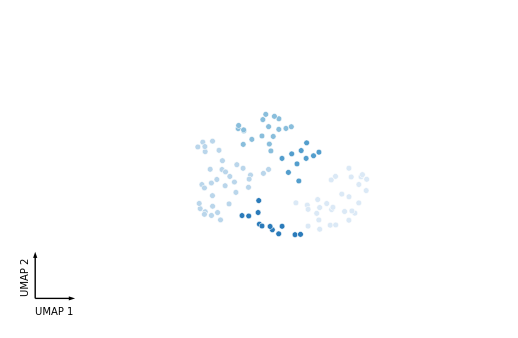

In [ ]:
##############
###                    NO
###                   THESE ARE FOR POSTIVES


G = nx.from_scipy_sparse_matrix(mapper.graph_)
clustering = cylouvain.best_partition(G, resolution = RESOLUTION)
clustering_solution = list(clustering.values())
umap_df['color'] = clustering_solution

cluster_colors = [CUSTOM_PAL_SORT_4[i] for i in clustering_solution]
#cluster_colors = [blues[i] for i in clustering_solution]
###########

f,arr = plt.subplots(1,figsize=[7,4.5],tight_layout = {'pad': 0});
f.tight_layout()
arr.scatter(umap_df['x'].tolist(), umap_df['y'].tolist(),
            marker='o', c=cluster_colors, s=32, edgecolor='w',
            linewidth=0.5)
arr.spines['top'].set_visible(False)
arr.spines['bottom'].set_visible(False)
arr.spines['left'].set_visible(False)
arr.spines['right'].set_visible(False)
arr.set_xticks([]);
arr.set_yticks([]);
#arr.set_xlim(-10,20)
#arr.set_ylim(-3,9)
#arr.arrow(-8,-0.8,0,1.5, width=0.05, shape="full", ec="none", fc="black")
#arr.arrow(-8,-0.8,1.2,0, width=0.05, shape="full", ec="none", fc="black")

#arr.text(-8,-1.3,"UMAP 1", va="center")
#arr.text(-8.7,-0.7,"UMAP 2",rotation=90, ha="left", va="bottom")
############
arr.set_xlim(2,20)
arr.set_ylim(-5,7)

arr.arrow(3,-3.8,0,1.5, width=0.05, shape="full", ec="none", fc="black")
arr.arrow(3,-3.8,1.2,0, width=0.05, shape="full", ec="none", fc="black")

arr.text(3,-4.3,"UMAP 1", va="center")
arr.text(2.5,-3.7,"UMAP 2",rotation=90, ha="left", va="bottom")


N_CLUST = len(set(clustering_solution))
#f.savefig(figure2_path, bbox_inches='tight', format='pdf')
plt.savefig(figure2_path, dpi=300)

ValueError: ignored

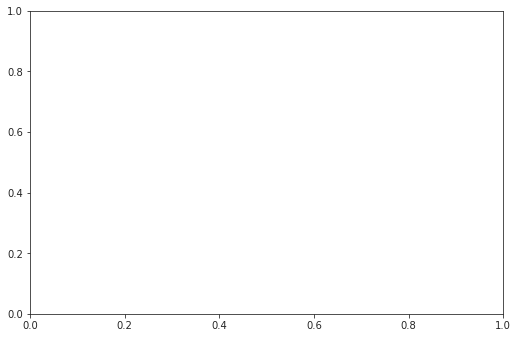

In [ ]:
########### NO.

f,arr = plt.subplots(1,figsize=[7,4.5],tight_layout = {'pad': 0});
f.tight_layout()
arr.scatter(umap_df['x'].tolist(), umap_df['y'].tolist(),
            marker='o', c=s.Depth, s=32, edgecolor='w',
            linewidth=0.5, cmap='PiYG')
arr.spines['top'].set_visible(False)
arr.spines['bottom'].set_visible(False)
arr.spines['left'].set_visible(False)
arr.spines['right'].set_visible(False)
arr.set_xticks([]);
arr.set_yticks([]);
arr.set_xlim(-10,20)
arr.set_ylim(-3,15)

#arr.set_xlim(-10,20)
#arr.set_ylim(-10,30)

arr.arrow(-8,-0.8,0,1.5, width=0.05, shape="full", ec="none", fc="black")
arr.arrow(-8,-0.8,1.2,0, width=0.05, shape="full", ec="none", fc="black")

arr.text(-8,-1.3,"UMAP 1", va="center")
arr.text(-8.7,-1.0,"UMAP 2",rotation=90, ha="left", va="bottom")

N_CLUST = len(set(clustering_solution))
f.savefig(figure2_path, bbox_inches='tight', format='pdf')


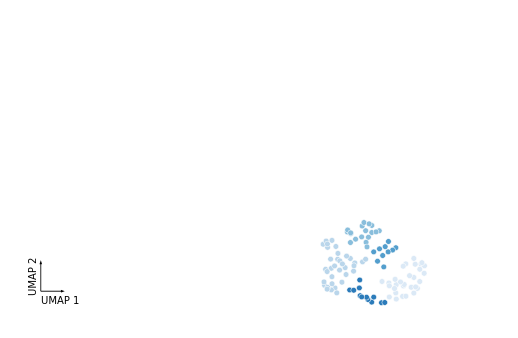

In [ ]:
###  NO.

reducer = umap.UMAP(n_neighbors = N_NEIGHBORS, min_dist=MIN_DIST,
                    random_state=RAND_STATE)
mapper = reducer.fit(full_data)
embedding = reducer.transform(full_data)

umap_df = pd.DataFrame(embedding, columns=('x', 'y'))
umap_df['waveform'] = list(full_data)





f,arr = plt.subplots(1,figsize=[7,4.5],tight_layout = {'pad': 0});
f.tight_layout()
arr.scatter(umap_df['x'].tolist(), umap_df['y'].tolist(),
            marker='o', c=cluster_colors, s=32, edgecolor='w',
            linewidth=0.5)
arr.spines['top'].set_visible(False)
arr.spines['bottom'].set_visible(False)
arr.spines['left'].set_visible(False)
arr.spines['right'].set_visible(False)
arr.set_xticks([]);
arr.set_yticks([]);
arr.set_xlim(-10,20)
arr.set_ylim(-3,15)

#arr.set_xlim(-10,20)
#arr.set_ylim(-10,30)

arr.arrow(-8,-0.8,0,1.5, width=0.05, shape="full", ec="none", fc="black")
arr.arrow(-8,-0.8,1.2,0, width=0.05, shape="full", ec="none", fc="black")

arr.text(-8,-1.3,"UMAP 1", va="center")
arr.text(-8.7,-1.0,"UMAP 2",rotation=90, ha="left", va="bottom")

N_CLUST = len(set(clustering_solution))
#f.savefig(figure2_path, bbox_inches='tight', format='pdf')
plt.savefig(figure2_path, dpi=300)

In [ ]:

#umap.plot.points(mapper, labels=s.Depth)
#umap.plot.connectivity(mapper, edge_bundling='hammer')

Plotting Individual Clusters

In [ ]:
# Defines a nice function that plots all the waveforms in long column.
def plot_group(label_ix, labels, groups_df, colors, mean_only=False, detailed=False):
    group_ixs = [i for i,x in enumerate(labels) if x == label_ix-1]
    group_waveforms = groups_df.iloc[group_ixs]['waveform'].tolist()

    f, arr = plt.subplots()
    f.set_figheight(1.8*0.65)
    f.set_figwidth(3.0*0.65)
    if not mean_only:
        for i,_ in enumerate(group_waveforms):
            plt.plot(group_waveforms[i],c=colors[label_ix-1],alpha=0.3,linewidth=1.5)

    if not mean_only:
        plt.plot(np.mean(group_waveforms,axis=0),c='k',linestyle='-')
    else:
        plt.plot(np.mean(group_waveforms,axis=0),c=colors[label_ix-1],linestyle='-')

    arr.spines['right'].set_visible(False)
    arr.spines['top'].set_visible(False)

    if detailed:

        avg_peak = np.mean([np.argmax(x) for x in group_waveforms[14:]])
        arr.axvline(avg_peak,color='k',zorder=0)

        arr.set_ylim([-1.3,1.3])
        arr.set_yticks([])
        arr.set_xticks([0,7,14,21,28,35,42,48])
        arr.tick_params(axis='both', which='major', labelsize=12)
        arr.set_xticklabels([0,'',0.5,'',1.0,'',1.5,''])
        arr.spines['left'].set_visible(False)
        arr.grid(False)
        arr.set_xlim([0,48])

    if not detailed:
        arr.set(xticks=[],yticks=[])

        if not mean_only:
            x,y = 2.1,0.7
            ellipse = mpl.patches.Ellipse((x,y), width=9.0, height=0.72, facecolor='w',
                                 edgecolor='k',linewidth=1.5)
            label = arr.annotate(str(label_ix), xy=(x-0.25, y-0.15),fontsize=12, color = 'k', ha="center")
            arr.add_patch(ellipse)

            if i != -1:
                x, y = 23,-0.7
                n_waveforms = plt.text(x, y,
                                       'n = '+str(len(group_waveforms))+
                                       ' ('+str(round(len(group_waveforms)/len(groups_df)*100,2))+'%)'
                                       , fontsize=10)

    return f, arr

In [ ]:
np.arange(1,nColors+1)

array([1, 2, 3, 4, 5, 6, 7, 8, 9])

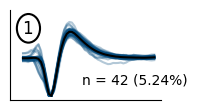

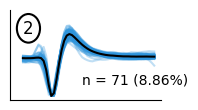

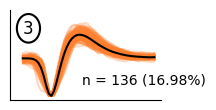

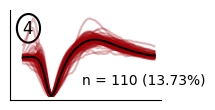

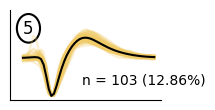

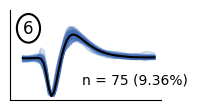

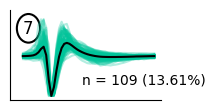

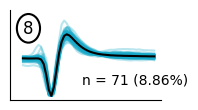

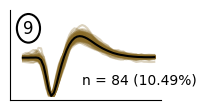

In [ ]:
BSclass = np.arange(1,nColors+1);#, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15] #, 16, 17, 18, 19, 20]
#posclass = [1, 2, 3, 4, 5, 6, 7];
#BSclass = [9] #, 7]
#NSclass = [2, 4]; #4, 5]
#for i in NSclass:
 #   plot_group(i,clustering_solution,umap_df,CUSTOM_PAL_SORT_3)
    #plt.savefig(clusters3_path, bbox_inches='tight', format='eps')



for i in BSclass:
    curr_path = "clusters{}_path".format(i);
    plot_group(i,clustering_solution,umap_df,CUSTOM_PAL_SORT_3)
    #plt.savefig(clusters9_path, bbox_inches='tight', format='eps')
    #print("clusters{}_path".format(i))


#for i in NSclass:
#   plot_group(i,clustering_solution,umap_df,CUSTOM_PAL_SORT_3)


#for i in posclass:
 #   plot_group(i,clustering_solution,umap_df,CUSTOM_PAL_SORT_3)
# 60.7% broad, 39.2% narrow#

In [ ]:
# Defines a nice function that plots all the waveforms in long column.
def plot_groups(label_ix, labels, groups_df, colors, mean_only=False, detailed=False):
    group_ixs = [i for i,x in enumerate(labels) if x == label_ix-1]
    group_waveforms = groups_df.iloc[group_ixs]['waveform'].tolist()

    #print(group_waveforms.shape)

    f, arr = plt.subplots()
    f.set_figheight(1.8*0.65)
    f.set_figwidth(3.0*0.65)
    if not mean_only:
        for i,_ in enumerate(group_waveforms):
            plt.plot(group_waveforms[i],c=colors[label_ix-1],alpha=0.3,linewidth=1.5)

    if not mean_only:
        plt.plot(np.mean(group_waveforms,axis=0),c='k',linestyle='-')
    else:
        plt.plot(np.mean(group_waveforms,axis=0),c=colors[label_ix-1],linestyle='-')

    arr.spines['right'].set_visible(False)
    arr.spines['top'].set_visible(False)

    if detailed:

        avg_peak = np.mean([np.argmax(x) for x in group_waveforms[14:]])
        arr.axvline(avg_peak,color='k',zorder=0)

        arr.set_ylim([-1.3,1.3])
        arr.set_yticks([])
        arr.set_xticks([0,7,14,21,28,35,42,48])
        arr.tick_params(axis='both', which='major', labelsize=12)
        arr.set_xticklabels([0,'',0.5,'',1.0,'',1.5,''])
        arr.spines['left'].set_visible(False)
        arr.grid(False)
        arr.set_xlim([0,48])

    if not detailed:
        arr.set(xticks=[],yticks=[])

        if not mean_only:
            x,y = 2.1,0.7
            ellipse = mpl.patches.Ellipse((x,y), width=9.0, height=0.72, facecolor='w',
                                 edgecolor='k',linewidth=1.5)
            label = arr.annotate(str(label_ix), xy=(x-0.25, y-0.15),fontsize=12, color = 'k', ha="center")
            arr.add_patch(ellipse)

            if i != -1:
                x, y = 23,-0.7
                n_waveforms = plt.text(x, y,
                                       'n = '+str(len(group_waveforms))+
                                       ' ('+str(round(len(group_waveforms)/len(groups_df)*100,2))+'%)'
                                       , fontsize=10)

    return f, arr

In [ ]:
NSclass = [1, 2]

for i in NSclass:
    plot_groups(i,clustering_solution,umap_df,CUSTOM_PAL_SORT_3,mean_only=True)


KeyError: 'waveform'

In [ ]:
print(depth_data.shape)

g = np.transpose(np.array([clustering_solution]))
m = np.column_stack((g,depth_data,ID_data, umap_df['x'], umap_df['y']))
n = pd.Series([m])
df1 = pd.DataFrame(m,columns=list(['Cluster','Depth','ID','Session','umap_x','umap_y']))


s = df1

s['Cluster'] = s['Cluster']+1;
narrow = pd.concat([s.loc[lambda df: df['Cluster'] == 1, :], s.loc[lambda df: df['Cluster'] == 2, :]]) #, s.loc[lambda df: df['cluster'] == 4, :]])
broad = pd.concat([s.loc[lambda df: df['Cluster'] == 0, :], s.loc[lambda df: df['Cluster'] == 3, :]]) #, s.loc[lambda df: df['cluster'] == 3, :]])

print(s)

(801, 1)
     Cluster       Depth     ID  Session    umap_x    umap_y
0        7.0 -940.518888    4.0      1.0 -1.169324  4.762546
1        7.0 -913.275822    6.0      1.0 -1.648270  5.938853
2        7.0 -623.875978   36.0      1.0 -1.776223  5.503817
3        7.0 -573.055164   39.0      1.0 -1.191064  6.511539
4        7.0 -573.055164   40.0      1.0 -0.857606  6.977725
..       ...         ...    ...      ...       ...       ...
796      7.0         NaN  666.0      5.0 -1.003249  6.816649
797      7.0         NaN  672.0      5.0 -1.094053  4.723335
798      7.0         NaN  673.0      5.0 -1.439468  5.060314
799      3.0  235.471315  674.0      5.0  4.808022  5.995315
800      6.0         NaN  676.0      5.0  4.503773  4.565160

[801 rows x 6 columns]


In [ ]:
#Saving ECG Results
print(depth_data.shape)

g = np.transpose(np.array([clustering_solution]))
m = np.column_stack((g,depth_data,ID_data, umap_df['x'], umap_df['y']))
n = pd.Series([m])
df1 = pd.DataFrame(m,columns=list(['Cluster','Depth','ID','Session','umap_x','umap_y']))


s = df1

In [ ]:
g = np.transpose(np.array([clustering_solution]))
m = np.column_stack((g,depth_data,ID_data, umap_df['x'], umap_df['y']))
n = pd.Series([m])
df1 = pd.DataFrame(m,columns=list(['Cluster','Depth','ID','Session','umap_x','umap_y']))


s = df1.loc[lambda df: df['Depth'] <3000, :]

s['Cluster'] = s['Cluster']+1;
narrow = pd.concat([s.loc[lambda df: df['Cluster'] == 1, :], s.loc[lambda df: df['Cluster'] == 2, :]]) #, s.loc[lambda df: df['cluster'] == 4, :]])
broad = pd.concat([s.loc[lambda df: df['Cluster'] == 0, :], s.loc[lambda df: df['Cluster'] == 3, :]]) #, s.loc[lambda df: df['cluster'] == 3, :]])

maxsession = 5
sessionIDs = np.arange(4,maxsession+1)
iloc, sessionsidx = ismember(s['Session'], sessionIDs) ;
print(sessionIDs)
  #print(a.shape)
  #full_data = full_data[iloc];
corrected_depth_data = s['Depth'][iloc] *-1 ;
  #ID_data = ID_data[iloc];
  #print(full_data.shape)
s['Depth'][iloc] = corrected_depth_data;
  #s['Depth'] = s['Depth'][s['Depth'] > -990]
  #S = df1.loc[]
print(s)




#b = plt.subplot(sns.violinplot(data=depth_data))

#c = sns.displot(data=clustering_solution)

[4 5]
     Cluster       Depth     ID  Session    umap_x    umap_y
0        5.0 -940.518888    4.0      1.0 -1.505076  0.375283
1        5.0 -913.275822    6.0      1.0 -2.825894  0.765272
2        5.0 -623.875978   36.0      1.0 -2.495226  0.319410
3        5.0 -573.055164   39.0      1.0 -2.632046  1.842499
4        5.0 -573.055164   40.0      1.0 -2.955933  2.010118
..       ...         ...    ...      ...       ...       ...
788      3.0 -285.400000  634.0      5.0  9.023368  4.657588
789      4.0 -313.048255  635.0      5.0  6.603059  4.360065
792      2.0 -294.529884  652.0      5.0  4.526382  5.300941
793      1.0 -615.611792  657.0      5.0 -1.651936  2.766877
794      5.0 -395.907833  661.0      5.0 -2.299167  0.957003

[568 rows x 6 columns]



A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


In [ ]:



GG = np.transpose(np.array([clustering_solution]))
M = np.column_stack((GG,depth_data,ID_data))
N = pd.Series([M])
df2 = pd.DataFrame(m,columns=list(['Cluster','Depth','ID','Session']))

S = df2.loc[lambda df: df['Depth'] < 990, :]

S['Cluster'] = S['Cluster']+6;
narrow = pd.concat([S.loc[lambda df: df['Cluster'] == 1, :], S.loc[lambda df: df['Cluster'] == 2, :]]) #, s.loc[lambda df: df['cluster'] == 4, :]])
broad = pd.concat([S.loc[lambda df: df['Cluster'] == 0, :], S.loc[lambda df: df['Cluster'] == 3, :]]) #, s.loc[lambda df: df['cluster'] == 3, :]])

maxsession = 5
sessionIDs = np.arange(4,maxsession+1)
iloc, sessionsidx = ismember(s['Session'], sessionIDs);
print(sessionIDs)
#print(a.shape)
#full_data = full_data[iloc];
corrected_depth_data = S['Depth'][iloc] *-1 ;
#ID_data = ID_data[iloc];
#print(full_data.shape)
S['Depth'][iloc] = corrected_depth_data;

#S = df1.loc[]
print(S)




#b = plt.subplot(sns.violinplot(data=depth_data))

#c = sns.displot(data=clustering_solution)

NameError: ignored

In [ ]:
cluster_data = pd.DataFrame.to_csv(df1)
df1.to_csv(r'drive/MyDrive/Chand Lab/Shude Data/9 13 2022/cluster_data.csv',index = False, header=True)

In [ ]:
poscluster_data = pd.DataFrame.to_csv(df2)
df2.to_csv(r'drive/MyDrive/Chand Lab/Shude Data/poscluster_data.csv',index = False, header=True)


Confusion Matrix


In [ ]:
testSize = 0.3;

UMAP_X = np.stack(umap_df['waveform'].to_numpy().tolist(), axis=0)
UMAP_y = umap_df['color'].to_numpy()

unclassified_ixs = [ix for ix,clust in enumerate(UMAP_y) if clust == -1]

UMAP_X = np.delete(UMAP_X,unclassified_ixs,axis=0)
UMAP_y = np.delete(UMAP_y,unclassified_ixs,axis=0)

UMAP_X_train, UMAP_X_test, UMAP_y_train, UMAP_y_test = train_test_split(UMAP_X, UMAP_y, test_size=testSize, random_state=RAND_STATE)

In [ ]:
numCV = 5

UMAP_model = xgb.XGBClassifier()
UMAP_param_dist = {"max_depth": [4],
              "min_child_weight" : [2.5],
              "n_estimators": [100],
              "learning_rate": [0.3],
              "seed": [RAND_STATE]}
UMAP_grid_search = GridSearchCV(UMAP_model, param_grid=UMAP_param_dist,
                           cv = numCV,
                           verbose=10, n_jobs=-1)
UMAP_grid_search.fit(UMAP_X_train, UMAP_y_train)

confusion_matrix(UMAP_y_test,UMAP_grid_search.predict(UMAP_X_test))

Fitting 5 folds for each of 1 candidates, totalling 5 fits


ERROR:concurrent.futures:exception calling callback for <Future at 0x7f05bdbfab50 state=finished raised BrokenProcessPool>
joblib.externals.loky.process_executor._RemoteTraceback: 
"""
Traceback (most recent call last):
  File "/usr/local/lib/python3.7/dist-packages/joblib/externals/loky/process_executor.py", line 407, in _process_worker
    call_item = call_queue.get(block=True, timeout=timeout)
  File "/usr/lib/python3.7/multiprocessing/queues.py", line 113, in get
    return _ForkingPickler.loads(res)
AttributeError: Can't get attribute '_FuncWrapper' on <module 'sklearn.utils.fixes' from '/usr/local/lib/python3.7/dist-packages/sklearn/utils/fixes.py'>
"""

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "/usr/local/lib/python3.7/dist-packages/joblib/externals/loky/_base.py", line 625, in _invoke_callbacks
    callback(self)
  File "/usr/local/lib/python3.7/dist-packages/joblib/parallel.py", line 359, in __call__
    se

BrokenProcessPool: ignored

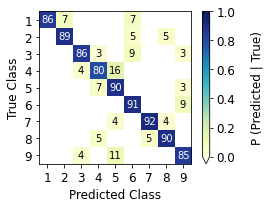

In [ ]:
confusion_mat_counts = confusion_matrix(UMAP_y_test,UMAP_grid_search.predict(UMAP_X_test))

conf_mat_row_list = []

for row in confusion_mat_counts:
    row_sum = np.sum(row)

    row_percent = []

    for val in row:
        row_percent.append(val/row_sum)

    conf_mat_row_list.append(row_percent)

conf_mat = np.array(conf_mat_row_list)

colormap = mpl.cm.YlGnBu
colormap.set_under('white')

eps = np.spacing(0.0)
f, arr = plt.subplots(1,figsize=[4,3])
mappable = arr.imshow(conf_mat,cmap=colormap,vmin=eps,vmax=1.)
color_bar = f.colorbar(mappable, ax=arr, extend='min')
color_bar.set_label('P (Predicted | True)',fontsize=12,labelpad=15,fontname="Arial")
color_bar.ax.tick_params(size=3,labelsize=12)

#Specify label behavior of the main diagonal
for i in range(0,N_CLUST):
    if int(conf_mat[i,i]*100) == 100:
        arr.text(i-0.38,i+0.17,int(round(conf_mat[i,i]*100)),fontsize=10,c='white',fontname="Arial")
    else:
        arr.text(i-0.34,i+0.16,int(round(conf_mat[i,i]*100)),fontsize=10,c='white',fontname="Arial")

#Specify label behavior of the off-diagonals
for i in range(0,N_CLUST):
    for j in range(0,N_CLUST):
        if conf_mat[i,j] < 0.1 and conf_mat[i,j] != 0:
            arr.text(j-0.2,i+0.15,int(round(conf_mat[i,j]*100)),fontsize=10,c='k',fontname="Arial")
        elif conf_mat[i,j] >= 0.1 and conf_mat[i,j] < 0.5 and conf_mat[i,j] != 0:
            arr.text(j-0.4, i+0.15,int(round(conf_mat[i,j]*100)),fontsize=10,c='k',fontname="Arial")

arr.set_xticks(range(0,N_CLUST))
arr.set_xticklabels(range(1,N_CLUST+1),fontsize=12);
arr.set_yticks(range(0,N_CLUST))
arr.set_yticklabels(range(1,N_CLUST+1),fontsize=12);
arr.set_xlabel('Predicted Class',fontsize=12);
arr.set_ylabel('True Class',fontsize=12);
plt.tight_layout()
#plt.savefig(figure9_path, bbox_inches='tight', format='pdf')
#plt.savefig(figure9_path, dpi=300)

In [ ]:
#plt.savefig(figure9_path, bbox_inches='tight', format='pdf')

<Figure size 432x288 with 0 Axes>

Laminar depths

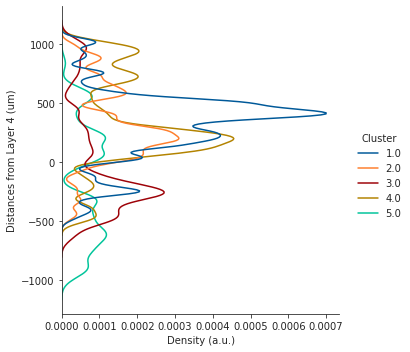

In [ ]:
customPalette = sns.color_palette(CUSTOM_PAL_SORT_3)
CustomPalette = sns.color_palette(CUSTOM_PAL_SORT_4)
narrowPalette = sns.color_palette(CUSTOM_PAL_SORT_3)#(Cold_colors)
broadPalette = sns.color_palette(Warm_colors)
sns.set_style("ticks")

f = sns.displot(y='Depth', hue='Cluster', data=s, kind='kde', bw_adjust = 0.3, palette=customPalette)

f.set_axis_labels('Density (a.u.)', 'Distances from Layer 4 (um)')

In [ ]:
####### This is laminar 1

#sns.displot(y='Depth', hue='Cluster', data=s, kde=True, palette=customPalette, )
#
#sns.histplot(y='depth',data=narrow,multiple='stack',bins=18,kde = True,kde_kws={},hue='cluster',palette=narrowPalette)
sns.histplot(y='Depth',data=s,bins=18,element='step',kde = True,kde_kws={},hue='Cluster',palette=customPalette)
#plt.plot([0, 52],[572,572],'--',color = 'black',lw=1)
#plt.plot([0, 52],[279,279],'--',color = 'black',lw=1)
#plt.plot([0, 52],[0,0],'--',color = 'black',lw=1)
#plt.plot([0, 52],[-562,-562],'--',color = 'black',lw=1)

plt.plot([0, 30],[588.8, 588.8],'--',color = 'black',lw=1)
plt.plot([0, 30],[285.4, 285.4],'--',color = 'black',lw=1)
plt.plot([0, 30],[0,0],'--',color = 'black',lw=1)
plt.plot([0, 30],[-488, -488],'--',color = 'black',lw=1)
plt.ylabel('Distance from Layer 4 (um)')
#plt.legend(loc='upper right')

plt.show
#plt.savefig(figure7_path, bbox_inches='tight', format='pdf')
#plt.savefig(figure7_path, dpi=300)
print(s.shape)

NameError: ignored

In [ ]:
#define data
data = [15, 25, 25, 30, 5]
labels = ['Group 1', 'Group 2', 'Group 3', 'Group 4', 'Group 5']

#define Seaborn color palette to use
colors = sns.color_palette('pastel')[0:5]

#create pie chart
plt.pie(data = s, labels = labels, colors = colors, autopct='%.0f%%')
plt.show()

In [ ]:
###### POS



#sns.displot(y='Depth', hue='Cluster', data=s, kde=True, palette=customPalette, )
#
#sns.histplot(y='depth',data=narrow,multiple='stack',bins=18,kde = True,kde_kws={},hue='cluster',palette=narrowPalette)
sns.histplot(y='Depth',data=s,bins=18,element='step',kde = True,kde_kws={},hue='Cluster',palette=CustomPalette)
#plt.plot([0, 52],[572,572],'--',color = 'black',lw=1)
#plt.plot([0, 52],[279,279],'--',color = 'black',lw=1)
#plt.plot([0, 52],[0,0],'--',color = 'black',lw=1)
#plt.plot([0, 52],[-562,-562],'--',color = 'black',lw=1)

plt.plot([0, 20],[588.8, 588.8],'--',color = 'black',lw=1)
plt.plot([0, 20],[285.4, 285.4],'--',color = 'black',lw=1)
plt.plot([0, 20],[0,0],'--',color = 'black',lw=1)
plt.plot([0, 20],[-488, -488],'--',color = 'black',lw=1)
plt.ylabel('Distance from Layer 4 (um)')
#plt.legend(loc='upper right')

plt.show
#plt.savefig(figure7_path, bbox_inches='tight', format='pdf')
#plt.savefig(figure7_path, dpi=300)
print(narrow.shape)


ValueError: ignored

(113, 6)


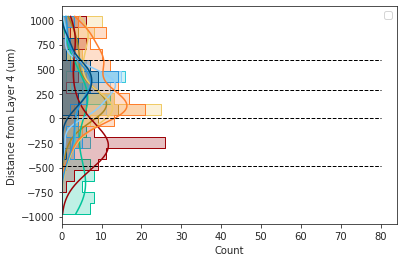

In [ ]:
sns.histplot(y='Depth',data=s,bins=18,element='step',kde = True,kde_kws={},hue='Cluster',palette=customPalette)
#sns.histplot(y='Depth',data=S,bins=18,element='step',kde = True,kde_kws={},hue='Cluster',palette=CustomPalette)
plt.plot([0, 80],[588.8, 588.8],'--',color = 'black',lw=1)
plt.plot([0, 80],[285.4, 285.4],'--',color = 'black',lw=1)
plt.plot([0, 80],[0,0],'--',color = 'black',lw=1)
plt.plot([0, 80],[-488, -488],'--',color = 'black',lw=1)
plt.ylabel('Distance from Layer 4 (um)')
plt.legend(loc='upper right')

plt.show
#plt.savefig(figure7_path, bbox_inches='tight', format='pdf')
print(narrow.shape)

Text(-5.972526041666669, 0.5, 'Distance from Layer 4 (um)')

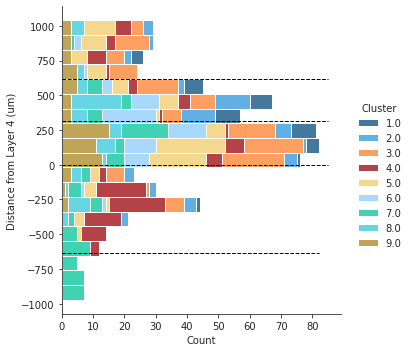

In [ ]:
sns.displot(y='Depth', hue='Cluster', data=s,multiple='stack', palette=customPalette)
plt.plot([0, 85],[1610-990,1610-990],'--',color = 'black',lw=1)
plt.plot([0, 85],[1302-990,1302-990],'--',color = 'black',lw=1)
plt.plot([0, 85],[990-990,990-990],'--',color = 'black',lw=1)
plt.plot([0, 82],[353-990,353-990],'--',color = 'black',lw=1)
plt.ylabel('Distance from Layer 4 (um)')

In [ ]:
print(broad.shape)


(125, 3)


In [ ]:
#sns.histplot(y='depth',data=broad,multiple='stack',bins=18,kde=True,kde_kws={},hue='cluster',palette=broadPalette)
sns.histplot(y='Depth',data=broad,element='step',bins=18,kde=True,kde_kws={},hue='Cluster',palette=broadPalette) #element='step'
plt.plot([0, 45],[1610-990,1610-990],'--',color = 'black',lw=1)
plt.plot([0, 45],[1302-990,1302-990],'--',color = 'black',lw=1)
plt.plot([0, 45],[990-990,990-990],'--',color = 'black',lw=1)
plt.plot([0, 45],[353-990,353-990],'--',color = 'black',lw=1)
plt.ylabel('Distance from Layer 4 (um)')
print(broad.shape)

ValueError: ignored

In [ ]:



#sns.histplot(y='depth',data=narrow,multiple='stack',bins=18,kde = True,kde_kws={},hue='cluster',palette=narrowPalette)
sns.histplot(y='Depth',data=narrow,element='step',bins=18,kde = True,kde_kws={},hue='Cluster',palette=narrowPalette)
plt.plot([0, 45],[1610-990,1610-990],'--',color = 'black',lw=1)
plt.plot([0, 45],[1302-990,1302-990],'--',color = 'black',lw=1)
plt.plot([0, 45],[990-990,990-990],'--',color = 'black',lw=1)
plt.plot([0, 45],[353-990,353-990],'--',color = 'black',lw=1)
plt.ylabel('Distance from Layer 4 (um)')
plt.show
print(narrow.shape)

ValueError: ignored

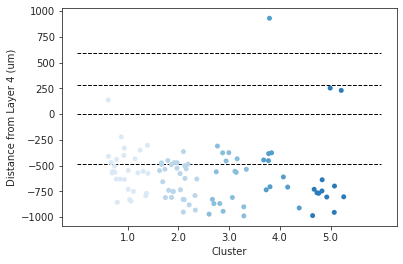

In [ ]:
#crest = sns.color_palette("crest")
sns.stripplot(x='Cluster', y='Depth', data=s, palette=CustomPalette,jitter=0.4)


plt.plot([-1, 5],[588.8, 588.8],'--',color = 'black',lw=1)
plt.plot([-1, 5],[285.4, 285.4],'--',color = 'black',lw=1)
plt.plot([-1, 5],[0,0],'--',color = 'black',lw=1)
plt.plot([-1, 5],[-488, -488],'--',color = 'black',lw=1)
plt.ylabel('Distance from Layer 4 (um)')
#plt.savefig(figure8_path, bbox_inches='tight', format='pdf')
plt.savefig(figure8_path, dpi=300)

Text(0, 0.5, 'Distance from Layer 4 (um)')

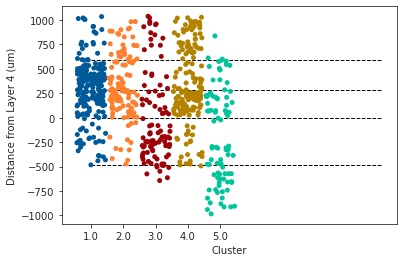

In [ ]:
####### This is laminar 2

#crest = sns.color_palette("crest")
sns.stripplot(x='Cluster', y='Depth', data=s, palette=customPalette,jitter=0.45)
plt.plot([0, 9],[588.8, 588.8],'--',color = 'black',lw=1)
plt.plot([0, 9],[285.4, 285.4],'--',color = 'black',lw=1)
plt.plot([0, 9],[0,0],'--',color = 'black',lw=1)
plt.plot([0, 9],[-488, -488],'--',color = 'black',lw=1)
plt.ylabel('Distance from Layer 4 (um)')
#plt.savefig(figure8_path, bbox_inches='tight', format='pdf')
#plt.savefig(figure8_path, dpi=300)

Text(0, 0.5, 'Distance from Layer 4 (um)')

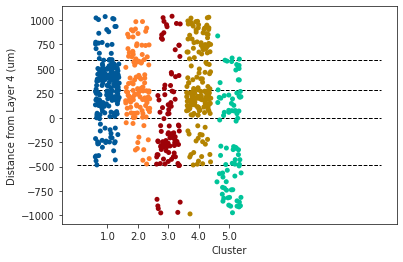

In [ ]:
########### JK this is laminar 2


#sns.stripplot(x='Cluster', y='Depth', data=S,palette=CustomPalette,jitter=0.4)
sns.stripplot(x='Cluster', y='Depth', data=s, palette=customPalette,jitter=0.4)

plt.plot([-1, 9],[588.8, 588.8],'--',color = 'black',lw=1)
plt.plot([-1, 9],[285.4, 285.4],'--',color = 'black',lw=1)
plt.plot([-1, 9],[0,0],'--',color = 'black',lw=1)
plt.plot([-1, 9],[-488, -488],'--',color = 'black',lw=1)
plt.ylabel('Distance from Layer 4 (um)')
#plt.savefig(figure8_path, bbox_inches='tight', format='pdf')
#plt.savefig(figure8_path, dpi=300)

In [ ]:
# STOP. THIS STEP TAKES 40 MINUTES.
# STOP. THIS STEP TAKES 40 MINUTES.
# STOP. THIS STEP TAKES 40 MINUTES.
# STOP. THIS STEP TAKES 40 MINUTES.
# STOP. THIS STEP TAKES 40 MINUTES.
# STOP. THIS STEP TAKES 40 MINUTES.

resolution_list = np.linspace(0,10,21)
modularity_dict = {}
n_clusts_dict = {}

subsets=[100]

for res in resolution_list:
    print("\n" + BlueCol + str(res))
    for frac in subsets:
        rand_list = []
        n_clusts = []
        for i in list(range(1,25)):
            reducer_rand_test = umap.UMAP(n_neighbors = N_NEIGHBORS,
                                     min_dist=MIN_DIST,
                                     random_state=random.randint(1,100000))
            rand_data = np.random.permutation(full_data)[0:(int(len(full_data)*frac)),:]
            mapper = reducer_rand_test.fit(rand_data)
            embedding_rand_test = reducer_rand_test.transform(rand_data)

            umap_df_rand_test = pd.DataFrame(embedding_rand_test, columns=('x', 'y'))
            G = nx.from_scipy_sparse_matrix(mapper.graph_)
            clustering = cylouvain.best_partition(G, resolution = res)
            modularity = cylouvain.modularity(clustering, G)
            clustering_solution = list(clustering.values())
            rand_list.append(modularity)
            n_clusts.append(len(set(clustering_solution)))
        modularity_dict.update({str(res): rand_list})
        n_clusts_dict.update({str(res): n_clusts})


0.0

0.5

1.0

1.5

2.0

2.5

3.0

3.5

4.0

4.5

5.0

5.5

6.0

6.5

7.0

7.5

8.0

8.5

9.0

9.5

10.0


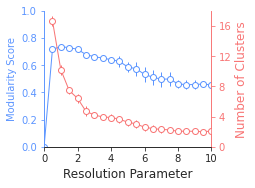

In [ ]:
# STOP. THIS IS GRAPHING THE MODULATION INDEX AND CAN ONLY BE DONE AFTER THE ABOVE STEP


resolution_list = np.linspace(0,10,21)

if 'n_clusts_dict' not in list(locals().keys()):
  n_clusts_dict = pkl.load(open('WaveMAP_Paper/data/n_clusts_dict.pkl','rb'))

if 'modularity_dict' not in list(locals().keys()):
  modularity_dict = pkl.load(open('WaveMAP_Paper/data/modularity_dict.pkl','rb'))

avg_n_clusts = []
for k in list(n_clusts_dict.keys()):
    avg_n_clusts.append(np.mean(n_clusts_dict[k]))

std_n_clusts = []
for k in list(n_clusts_dict.keys()):
    std_n_clusts.append(np.std(n_clusts_dict[k]))

std_modularity = []
for k in list(modularity_dict.keys()):
    std_modularity.append(np.std(modularity_dict[k]))

avg_modularity = []
for k in list(modularity_dict.keys()):
    avg_modularity.append(np.mean(modularity_dict[k]))

f, ax1 = plt.subplots(figsize=[3,2.5])

ax1.errorbar(resolution_list,avg_modularity,yerr=std_modularity,
             c = '#5c95ff', marker='o', fillstyle='full', markerfacecolor='w',
             linewidth=1, markeredgewidth=1)
ax1.set_ylabel('Modularity Score')
ax1.set_xlabel('Resolution Parameter',fontsize=12)
ax1.set_xlim([0,10])
ax1.set_xticks([0,2,4,6,8,10])
ax1.yaxis.label.set_color('#5c95ff')
ax1.tick_params(axis='y',colors='#5c95ff')
ax1.set_ylim(0,1.0)
ax1.set_yticks([0,0.2,0.4,0.6,0.8,1.0])
# ax1.set_yticklabels([0.0,'',0.2,'',0.4,'',0.6,'',0.8,'',1.0],fontsize=12)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_color('#f87575')
ax1.spines['left'].set_color('#5c95ff')

ax2 = ax1.twinx()
ax2.errorbar(resolution_list[1:],avg_n_clusts[1:],yerr=std_n_clusts[1:],
            c = '#f87575', marker='o', fillstyle='full', markerfacecolor='w', linewidth=1, markeredgewidth=1)
ax2.set_ylabel('Number of Clusters',fontsize=12,c='#f87575')
# ax2.spines['left'].set_color('b')
ax2.tick_params(axis='y',colors='#f87575')
ax2.set_ylim([0,18])
ax2.set_yticks([0,4,8,12,16]);
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_color('#f87575')
ax2.spines['left'].set_color('#5c95ff')
plt.savefig(figure11_path, dpi=300)

In [ ]:
plt.savefig(figure11_path, dpi=300)

<Figure size 432x288 with 0 Axes>

     sepal_length  sepal_width  petal_length  petal_width    species
0             5.1          3.5           1.4          0.2     setosa
1             4.9          3.0           1.4          0.2     setosa
2             4.7          3.2           1.3          0.2     setosa
3             4.6          3.1           1.5          0.2     setosa
4             5.0          3.6           1.4          0.2     setosa
..            ...          ...           ...          ...        ...
145           6.7          3.0           5.2          2.3  virginica
146           6.3          2.5           5.0          1.9  virginica
147           6.5          3.0           5.2          2.0  virginica
148           6.2          3.4           5.4          2.3  virginica
149           5.9          3.0           5.1          1.8  virginica

[150 rows x 5 columns]


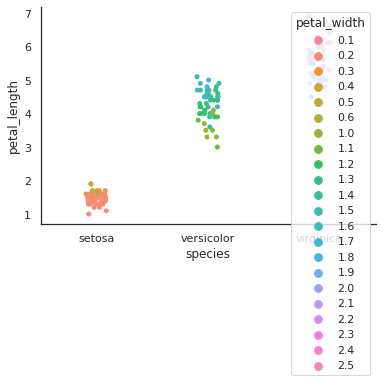

In [ ]:
iris = sns.load_dataset('iris')
sns.set(style="white", color_codes=True)
sns.stripplot(x='species', y='petal_length', hue='petal_width', data=iris)
sns.despine()
print(iris)